# 3.3. Bike Availability Prediction 1 Hour Ahead

The goal is predict a station's `bikes_available_to_rent` one hour into the future, so operators can plan bike transfers between stations.

**Structure:**

0. Data loading
1. Exploration
2. Target construction
3. Train / Test temporal split
4. Features (internal and external)
5. Baseline
7. Models: XGBoost and LightGBM
8. Evaluation - New dataset

## 0. Data loading

In [1]:
import os
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import xgboost as xgb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

ROOT = os.getcwd()
if os.path.basename(ROOT) == "notebooks":  # works from the project root or from notebooks/
    ROOT = os.path.dirname(ROOT)

In [2]:
status = pd.read_csv(ROOT + "/data_cleaned/stations_status_clean.csv")
stations = pd.read_csv(ROOT + "/data_cleaned/cleaned_stations.csv")
cities = pd.read_csv(ROOT + "/data_cleaned/cities_clean.csv")

In [3]:
status["time"] = pd.to_datetime(status["time"], utc=True)
status["local_time"] = pd.to_datetime(status["local_time"])
status = status.sort_values(["station_id", "time"]).reset_index(drop=True)

In [4]:
print(f"status:   {status.shape}")
print(f"stations: {stations.shape}")
print(f"cities:   {cities.shape}")
status.head()

status:   (2925807, 13)
stations: (2900, 8)
cities:   (267, 7)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,maint_change,timezone,local_time,hour,availability_mismatch
0,94,2022-08-29 13:12:01+00:00,5,0,5,0,0,False,NaN,Europe/Berlin,2022-08-29 15:12:01,15,False
1,94,2022-08-29 13:13:01+00:00,4,0,4,0,0,False,0.0,Europe/Berlin,2022-08-29 15:13:01,15,False
2,94,2022-08-30 13:30:01+00:00,5,0,5,0,0,False,0.0,Europe/Berlin,2022-08-30 15:30:01,15,False
3,94,2022-08-31 17:57:01+00:00,4,0,4,0,0,False,0.0,Europe/Berlin,2022-08-31 19:57:01,19,False
4,94,2022-08-31 18:05:01+00:00,5,0,5,0,0,False,0.0,Europe/Berlin,2022-08-31 20:05:01,20,False


---
## 1. Exploring `station_status`

Before building the problem, we need to understand how often a station's state is recorded. If it were a regular time series (one row every X minutes), it would be enough to look for the row closest to `t + 1h`.

In [5]:
# Time between two consecutive records of the same station
gap_min = status.groupby("station_id")["time"].diff().dt.total_seconds() / 60

print("Quantiles of the gap between events (minutes):")
print(gap_min.quantile([.10, .25, .50, .60, .75, .90, .99]).round(1))
print(f"\nGaps <= 5 min : {(gap_min <= 5).mean():.1%}")
print(f"Gaps <= 60 min: {(gap_min <= 60).mean():.1%}")

Quantiles of the gap between events (minutes):
0.10       1.0
0.25       4.0
0.50      28.0
0.60      54.0
0.75     158.0
0.90     722.0
0.99    4704.0
Name: time, dtype: float64

Gaps <= 5 min : 27.2%
Gaps <= 60 min: 61.6%


In [6]:
# Is every row a real state change? This represents how much that value changed vs the previous event of the same station
changes = status.groupby("station_id")[
    ["bikes_available_to_rent", "bikes", "booked_bikes", "free_racks", "free_special_racks"]
].diff().fillna(0)

In [7]:
changes.head()

,bikes_available_to_rent,bikes,booked_bikes,free_racks,free_special_racks
0,0.0,0.0,0.0,0.0,0.0
1,-1.0,-1.0,0.0,0.0,0.0
2,1.0,1.0,0.0,0.0,0.0
3,-1.0,-1.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,0.0


In [8]:
changes.describe()

,bikes_available_to_rent,bikes,booked_bikes,free_racks,free_special_racks
count,2.925807e+06,2.925807e+06,2.925807e+06,2.925807e+06,2.925807e+06
mean,-3.141014e-04,-3.328996e-04,-1.879823e-05,1.643991e-04,-1.124476e-04
std,1.257686e+00,1.245620e+00,2.636697e-01,9.650654e-01,6.402896e-01
min,-9.000000e+01,-9.000000e+01,-1.200000e+01,-2.900000e+01,-2.900000e+01
25%,-1.000000e+00,-1.000000e+00,0.000000e+00,-1.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
max,8.900000e+01,8.900000e+01,1.000000e+01,2.900000e+01,2.900000e+01


In [9]:
changes["bikes_available_to_rent"].value_counts(normalize=True)*100

bikes_available_to_rent
-1.0     41.523552
 1.0     40.760344
 0.0      7.562358
 2.0      3.988985
-2.0      3.861977
           ...    
 89.0     0.000034
-90.0     0.000034
-29.0     0.000034
 26.0     0.000034
-48.0     0.000034
Name: proportion, Length: 65, dtype: float64

- The mean of each column is ~0 (changes cancel out: it goes up and down equally), and there's an 89.84% chance that when an event is recorded, it's because 1 bike was added or removed at the station, or because it stayed the same (another parameter changed instead).
- There are extreme cases (min -90, max 89) that are almost certainly bulk rentals or bike rebalancing.

In [10]:
target_changed = changes["bikes_available_to_rent"] != 0
something_changed = (changes != 0).any(axis=1)

print(f"Rows that change bikes_available_to_rent    : {target_changed.mean():.1%}")
print(f"Of those that DON'T change it, something else changes: {something_changed[~target_changed].mean():.1%}")
print(f"Rows where only the time changes, nothing else: {(~something_changed).sum():,}")

Rows that change bikes_available_to_rent    : 92.4%
Of those that DON'T change it, something else changes: 98.5%
Rows where only the time changes, nothing else: 3,300


- `station_status`: It's an event log, not a regular series. We can see it because the time between two rows of the same station varies a lot (from 1 minute to several days), and almost every time a row appears it's because something changed (92.4% of the time `bikes_available_to_rent` changes).

### 1.1 Gaps in the stations' status log

In [11]:
all_times = np.sort(status["time"].unique())
gaps = np.diff(all_times)

big_gaps = np.where(gaps > np.timedelta64(90, "m"))[0]
outages = pd.DataFrame({
    "start": all_times[big_gaps],
    "end": all_times[big_gaps + 1],
})
outages["hours"] = (outages["end"] - outages["start"]) / np.timedelta64(1, "h")
outages = outages.sort_values("hours", ascending=False).reset_index(drop=True)
outages

,start,end,hours
0,2023-05-05 09:59:01+00:00,2023-05-17 08:21:01+00:00,286.366667
1,2022-09-17 14:59:01+00:00,2022-09-19 12:00:01+00:00,45.016667
2,2022-10-17 12:59:01+00:00,2022-10-18 12:27:01+00:00,23.466667
3,2023-06-26 18:43:01+00:00,2023-06-27 07:41:00+00:00,12.966389
4,2023-03-09 05:15:01+00:00,2023-03-09 13:06:01+00:00,7.850000


The longest outage goes from 2023-05-05 09:59:01+00:00 to 2023-05-17 08:21:01+00:00 (286 hours)

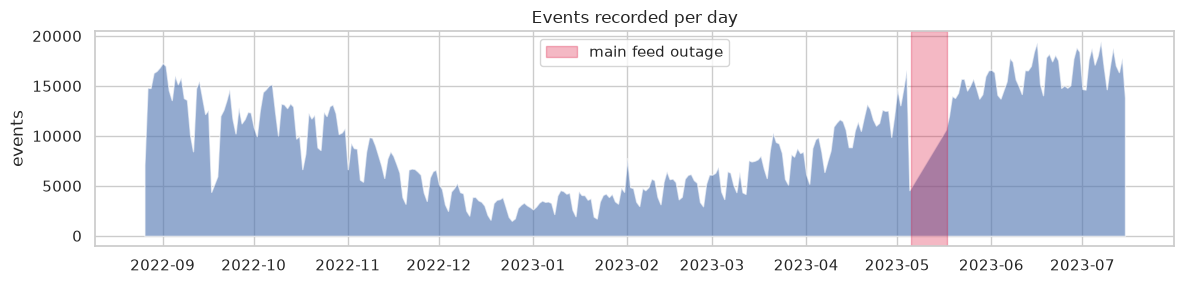

In [12]:
outage_start = outages.loc[0, "start"]
outage_end = outages.loc[0, "end"]

events_per_day = status.groupby(status["time"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 3))
ax.fill_between(pd.to_datetime(events_per_day.index), events_per_day.values, alpha=.6)
ax.axvspan(outage_start, outage_end, color="crimson", alpha=.3, label="main feed outage")
ax.set(title="Events recorded per day", xlabel="", ylabel="events")
ax.legend()
plt.tight_layout()

---
## 2. Target construction

The goal is to predict a station's `bikes_available_to_rent` one hour into the future, but we don't always have the 't + 1h' value for record 't' to train our model with.

However, from our analysis we saw that the system has a 92.4% chance that when a new record appears, it means `bikes_available_to_rent` changed, and a 98.5% chance that some other variable changed.

So, based on this, to build a dataset capable of predicting bike availability within 1h, we'll create a 't + 1h' record for each 't' record, based on the LOCF (*last observation carried forward*) method.

In [13]:
anchors = status[["station_id", "time", "bikes_available_to_rent"]].copy()
anchors = anchors.rename(columns={"bikes_available_to_rent": "y_now"})
anchors["target_time"] = anchors["time"] + pd.Timedelta(hours=1)

# "Future" table: same content as status, to look up the value at t+1h
future = status[["station_id", "time", "bikes_available_to_rent"]].rename(
    columns={"time": "obs_time", "bikes_available_to_rent": "y"}
).sort_values("obs_time")

anchors = anchors.sort_values("target_time")

# We compute the station's last real event at or right before the hour we want to predict
anchors = pd.merge_asof(
    anchors, future,
    left_on="target_time", right_on="obs_time",
    by="station_id", direction="backward",   # <- the last event BEFORE target_time
)
anchors["delta"] = anchors["y"] - anchors["y_now"]

print(f"target coverage: {anchors['y'].notna().mean():.2%}")
anchors.head()

target coverage: 100.00%


,station_id,time,y_now,target_time,obs_time,y,delta
0,286240,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,0,0
1,724351,2022-08-26 14:48:01+00:00,14,2022-08-26 15:48:01+00:00,2022-08-26 15:45:01+00:00,18,4
2,9799774,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 15:38:01+00:00,3,3
3,10213304,2022-08-26 14:48:01+00:00,4,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,4,0
4,33279179,2022-08-26 14:48:01+00:00,19,2022-08-26 15:48:01+00:00,2022-08-26 15:40:01+00:00,18,-1


In [14]:
100*anchors[anchors["y_now"]==anchors["y"]].shape[0]/anchors.shape[0]

53.04536491983237

In [15]:
# The target "y" was built with LOCF: if there's no event, we assume the station
# didn't change. How many of those labels rely on there being NO event at all during
# the next hour (pure silence), instead of being confirmed by a real event?
no_evidence = anchors["obs_time"] == anchors["time"]
print(f"anchors with no event at all in the following hour: {no_evidence.mean():.1%}")

anchors with no event at all in the following hour: 38.4%


In [16]:
# For those anchors, how long does it take for that station's NEXT real event to show up
# (even if it's after the hour we're predicting)? That tells us how long the silence
# actually is in practice.
status["next_event"] = status.groupby("station_id")["time"].shift(-1)
status["next_wait_min"] = (status["next_event"] - status["time"]).dt.total_seconds() / 60

wait = anchors.merge(
    status[["station_id", "time", "next_wait_min"]], on=["station_id", "time"], how="left"
).loc[no_evidence.to_numpy(), "next_wait_min"]

print("Of that 38%, the values aren't always filled in with something within the 1h \n" \
"look-back window; 38.4% get filled with a value from more than 1 hour ago:")
print((wait / 60).quantile([.25, .5, .75, .9, .99]).round(1))

Of that 38%, the values aren't always filled in with something within the 1h 
look-back window; 38.4% get filled with a value from more than 1 hour ago:
0.25      2.0
0.50      4.5
0.75     12.6
0.90     25.7
0.99    159.1
Name: next_wait_min, dtype: float64


We assume that if there's no event, the state didn't change — we can't verify this 100%, but it's reasonable because we already saw that the system records an event almost every time something changes (92.4%), so the absence of an event is the best clue we have that the station stayed the same.

### 2.1 Cleaning

In [17]:
# Case 1: Remove the multi-day gap between the stations' logs
in_outage = (anchors["target_time"] > outage_start) & (anchors["time"] < outage_end)

In [18]:
# Case 2: The station's last record won't have a t+1h.
last_event = status.groupby("station_id")["time"].max()
anchors["station_last_event"] = anchors["station_id"].map(last_event)
past_end = anchors["target_time"] > anchors["station_last_event"]

In [19]:
anchors["is_valid"] = ~(in_outage | past_end)
print(f"valid anchors: {anchors['is_valid'].mean():.2%}")

anchors = anchors[anchors["is_valid"]].drop(columns=["station_last_event", "is_valid"]).reset_index(drop=True)

valid anchors: 99.81%


P(delta == 0) = 53.02%


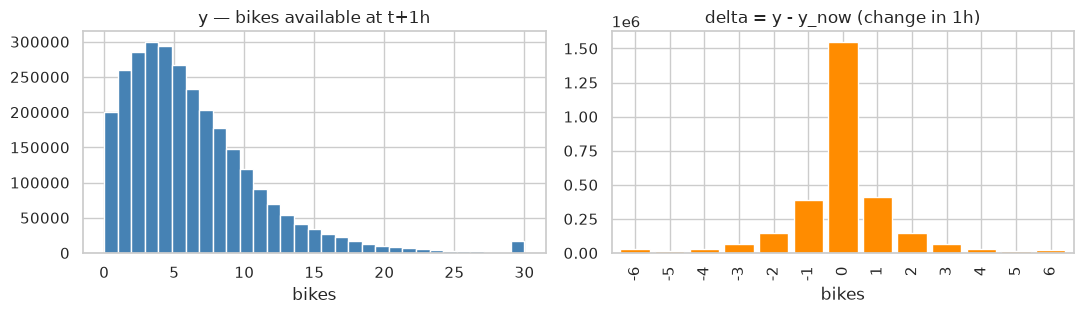

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
anchors["y"].clip(0, 30).hist(bins=31, ax=axes[0], color="steelblue")
axes[0].set(title="y — bikes available at t+1h", xlabel="bikes")

anchors["delta"].clip(-6, 6).value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange", width=.85)
axes[1].set(title="delta = y - y_now (change in 1h)", xlabel="bikes")
plt.tight_layout()

print(f"P(delta == 0) = {(anchors['delta'] == 0).mean():.2%}")

- The distribution of `delta` has almost half its mass at 0, which means that half the time nothing happens in an hour, so predicting no change at all is already right half the time. That's why we consider a persistence baseline model, i.e. one that doesn't change anything — bike availability stays the same as before.

- We'll use `delta` as the target instead of `y`, because that way the model focuses only on the change, instead of also having to rediscover the current value, which we already have (it's `y_now`). Also, if the model predicts delta=0 all the time, that's literally the same as persistence, so comparing against it is direct.

---
## 3. TRAIN/TEST Split

We split train (~75%) and test (~25%) respecting temporal order, and we also make sure to avoid data leaking into the future, leaving a 48h gap between train and test, since we have lag_24h variables that pull in past information.

In [21]:
TRAIN_END = pd.Timestamp("2023-06-01", tz="UTC")
TEST_START = pd.Timestamp("2023-06-03", tz="UTC")

conditions = [anchors["time"] < TRAIN_END, anchors["time"] >= TEST_START]
anchors["split"] = np.select(conditions, ["train", "test"], default="discarded")

anchors["split"].value_counts(normalize=True)*100

split
train        74.627292
test         24.243310
discarded     1.129397
Name: proportion, dtype: float64

---
## 4. Features

In [22]:
# 4.1 Current state of the row (already in status)
state_cols = ["bikes", "booked_bikes", "free_racks", "free_special_racks", "maintenance",
              "hour", "local_time"]
anchors = anchors.merge(status[["station_id", "time"] + state_cols], on=["station_id", "time"], how="left")

anchors["capacity"] = anchors["bikes"] + anchors["free_racks"]
anchors["fill_ratio"] = anchors["y_now"] / anchors["capacity"].replace(0, np.nan)
anchors["maintenance"] = anchors["maintenance"].astype(int)

anchors["dayofweek"] = anchors["local_time"].dt.dayofweek
anchors["is_weekend"] = (anchors["dayofweek"] >= 5).astype(int)

In [23]:
# 4.2 Minutes since the last event
# Strong signal: a station that just had activity is more likely to keep
# changing; one that's been quiet for hours is probably still the same.
status["minutes_since_last"] = status.groupby("station_id")["time"].diff().dt.total_seconds() / 60
anchors = anchors.merge(
    status[["station_id", "time", "minutes_since_last"]],
    on=["station_id", "time"], how="left",
)
anchors["minutes_since_last"] = anchors["minutes_since_last"].fillna(0)

In [ ]:
# 4.3 Past values (lags)
# Same LOCF trick as for the target, but looking backward instead of forward: "what value did the station have X hours ago?"
def value_n_hours_ago(anchors, log, hours):
    probe = anchors[["station_id", "time"]].reset_index(drop=True).copy()
    probe["original_order"] = np.arange(len(probe))
    probe["query_time"] = probe["time"] - pd.Timedelta(hours=hours)
    probe = probe.sort_values("query_time")

    short_log = log[["station_id", "time", "bikes_available_to_rent"]].rename(columns={"time": "obs_time"}).sort_values("obs_time")
    merged = pd.merge_asof(
        probe, short_log,
        left_on="query_time", right_on="obs_time",
        by="station_id", direction="backward",
    )
    merged = merged.sort_values("original_order")
    return merged["bikes_available_to_rent"].to_numpy()


anchors["lag_1h"] = value_n_hours_ago(anchors, status, 1)
anchors["lag_3h"] = value_n_hours_ago(anchors, status, 3)
anchors["lag_24h"] = value_n_hours_ago(anchors, status, 24)

# If there isn't enough history (anchors too early on), we assume nothing had changed.
for c in ["lag_1h", "lag_3h", "lag_24h"]:
    anchors[c] = anchors[c].fillna(anchors["y_now"])

In [25]:
# 4.4 Station's own data
anchors = anchors.merge(
    stations[["id", "bike_racks", "special_racks"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

### 4.5 Cyclical variables

`hour` and `dayofweek` aren't normal numbers: after hour 23 comes 0 (they're not
"far apart"), and after day 6 (Sunday) comes 0 (Monday). If we leave them as they are, the
model sees hour 23 and hour 0 as opposite extremes, when in reality they're almost the same
(both late at night). Turning them into sine and cosine gives that closeness explicitly, without
inventing any new data — it's just another way of representing the same thing.

In [26]:
anchors["hour_sin"] = np.sin(2 * np.pi * anchors["hour"] / 24)
anchors["dayofweek_sin"] = np.sin(2 * np.pi * anchors["dayofweek"] / 7)

In [27]:
anchors.head()

,station_id,time,y_now,target_time,obs_time,y,delta,split,bikes,booked_bikes,...,dayofweek,is_weekend,minutes_since_last,lag_1h,lag_3h,lag_24h,bike_racks,special_racks,hour_sin,dayofweek_sin
0,286240,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,0,0,train,0,0,...,4,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,-0.433884
1,724351,2022-08-26 14:48:01+00:00,14,2022-08-26 15:48:01+00:00,2022-08-26 15:45:01+00:00,18,4,train,14,0,...,4,0,0.0,14.0,14.0,14.0,22.0,0.0,-0.707107,-0.433884
2,9799774,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 15:38:01+00:00,3,3,train,0,0,...,4,0,0.0,0.0,0.0,0.0,15.0,0.0,-0.866025,-0.433884
3,10213304,2022-08-26 14:48:01+00:00,4,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,4,0,train,4,0,...,4,0,0.0,4.0,4.0,4.0,12.0,0.0,-0.866025,-0.433884
4,33279179,2022-08-26 14:48:01+00:00,19,2022-08-26 15:48:01+00:00,2022-08-26 15:40:01+00:00,18,-1,train,19,0,...,4,0,0.0,19.0,19.0,19.0,15.0,0.0,-0.866025,-0.433884


### 4.6 Weather (Open-Meteo)

Open-Meteo offers two different APIs, and the difference matters so we don't fool ourselves with
data leakage:

- **Archive API** (the one we use): ERA5 historical reanalysis — the weather that **actually
  happened** at each hour and city. It's reliable observational data, not a forecast.
- **Forecast API**: real forecasts, but only from "today" onward. It can't
  retroactively reconstruct "what would have been forecast" for a past date in 2023.

Since this project is a *backtest* over historical data, **we only use the weather at the anchor's
instant `t`**, never at `t+1h`. Using the one at `t+1h` would have meant treating data that already
happened as if it were a forecast — an approximation that works reasonably well 1 hour ahead, but
that isn't honest to present as a genuine forecast. Avoiding it removes any ambiguity about data
leakage.

In [28]:
# The station carries city_id in stations.csv; we use that to join its city's weather.
anchors = anchors.merge(
    stations[["id", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

weather_path = ROOT + "/data_external/weather_city.csv"

if os.path.exists(weather_path):
    weather = pd.read_csv(weather_path, parse_dates=["weather_time"])
    print("weather loaded from local cache")
else:
    print("weather cache doesn't exist, downloading from Open-Meteo...")
    cities_with_station = cities[cities["id"].isin(stations["city_id"].unique())].drop_duplicates("id")

    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": ",".join(cities_with_station["lat"].astype(str)),
        "longitude": ",".join(cities_with_station["lon"].astype(str)),
        "start_date": "2022-08-20",
        "end_date": "2023-07-20",
        "hourly": "temperature_2m,precipitation",
        "timezone": "UTC",
    }

    # Open-Meteo sometimes responds with 429 (too many requests); we retry after a short wait.
    for attempt in range(5):
        resp = requests.get(url, params=params, timeout=60)
        if resp.status_code != 429:
            break
        print(f"429 received, waiting before retrying (attempt {attempt + 1}/5)...")
        time.sleep(30)
    resp.raise_for_status()
    data = resp.json()   # one entry per city, in the same order as cities_with_station

    parts = []
    for city_id, block in zip(cities_with_station["id"], data):
        parts.append(pd.DataFrame({
            "city_id": city_id,
            "weather_time": pd.to_datetime(block["hourly"]["time"], utc=True),
            "wx_temp": block["hourly"]["temperature_2m"],
            "wx_precip": block["hourly"]["precipitation"],
        }))
    weather = pd.concat(parts, ignore_index=True)

    os.makedirs(ROOT + "/data_external", exist_ok=True)
    weather.to_csv(weather_path, index=False)
    print(f"weather downloaded and saved to {weather_path} so we don't repeat the download")

# Weather is at hourly resolution; we round the anchor's instant down to the exact
# hour (both in UTC) so we can join by (city_id, hour).
anchors["hour_utc"] = anchors["time"].dt.floor("h")
anchors = anchors.merge(
    weather[["city_id", "weather_time", "wx_temp", "wx_precip"]].rename(columns={"weather_time": "hour_utc"}),
    on=["city_id", "hour_utc"], how="left",
)

print(f"anchors without weather (no city or out of range): {anchors['wx_temp'].isna().mean():.2%}")
anchors[["station_id", "time", "city_id", "wx_temp", "wx_precip"]].head()

weather loaded from local cache
anchors without weather (no city or out of range): 0.76%


,station_id,time,city_id,wx_temp,wx_precip
0,286240,2022-08-26 14:48:01+00:00,88.0,23.1,0.6
1,724351,2022-08-26 14:48:01+00:00,320.0,22.0,0.0
2,9799774,2022-08-26 14:48:01+00:00,551.0,30.7,0.0
3,10213304,2022-08-26 14:48:01+00:00,570.0,29.6,0.0
4,33279179,2022-08-26 14:48:01+00:00,639.0,29.3,0.0


These correspond to the ones without a city_id, which we'll remove later on

In [29]:
anchors.isna().sum().sort_values(ascending=False)

fill_ratio            51130
bike_racks            22129
special_racks         22129
wx_precip             22129
city_id               22129
wx_temp               22129
station_id                0
split                     0
bikes                     0
time                      0
y_now                     0
target_time               0
obs_time                  0
y                         0
delta                     0
local_time                0
hour                      0
maintenance               0
free_special_racks        0
free_racks                0
booked_bikes              0
dayofweek                 0
capacity                  0
lag_24h                   0
lag_3h                    0
lag_1h                    0
minutes_since_last        0
is_weekend                0
hour_sin                  0
dayofweek_sin             0
hour_utc                  0
dtype: int64

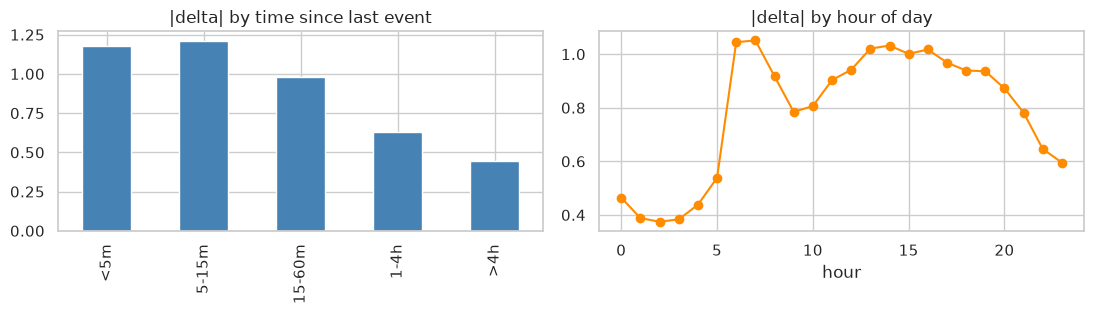

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))

b = pd.cut(anchors["minutes_since_last"], [-1, 5, 15, 60, 240, 1e9],
          labels=["<5m", "5-15m", "15-60m", "1-4h", ">4h"])
anchors.groupby(b, observed=True)["delta"].apply(lambda s: s.abs().mean()).plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="|delta| by time since last event", xlabel="")

anchors.groupby("hour")["delta"].apply(lambda s: s.abs().mean()).plot(ax=axes[1], marker="o", color="darkorange")
axes[1].set(title="|delta| by hour of day", xlabel="hour")
plt.tight_layout()

- In the `minutes_since_last` chart, you can see that the less time a station has gone without changing, the more likely it is to change soon.
- The station's own lags (1h/3h/24h) and the time since the last event capture recent behavior fairly well without needing to look at neighboring stations.

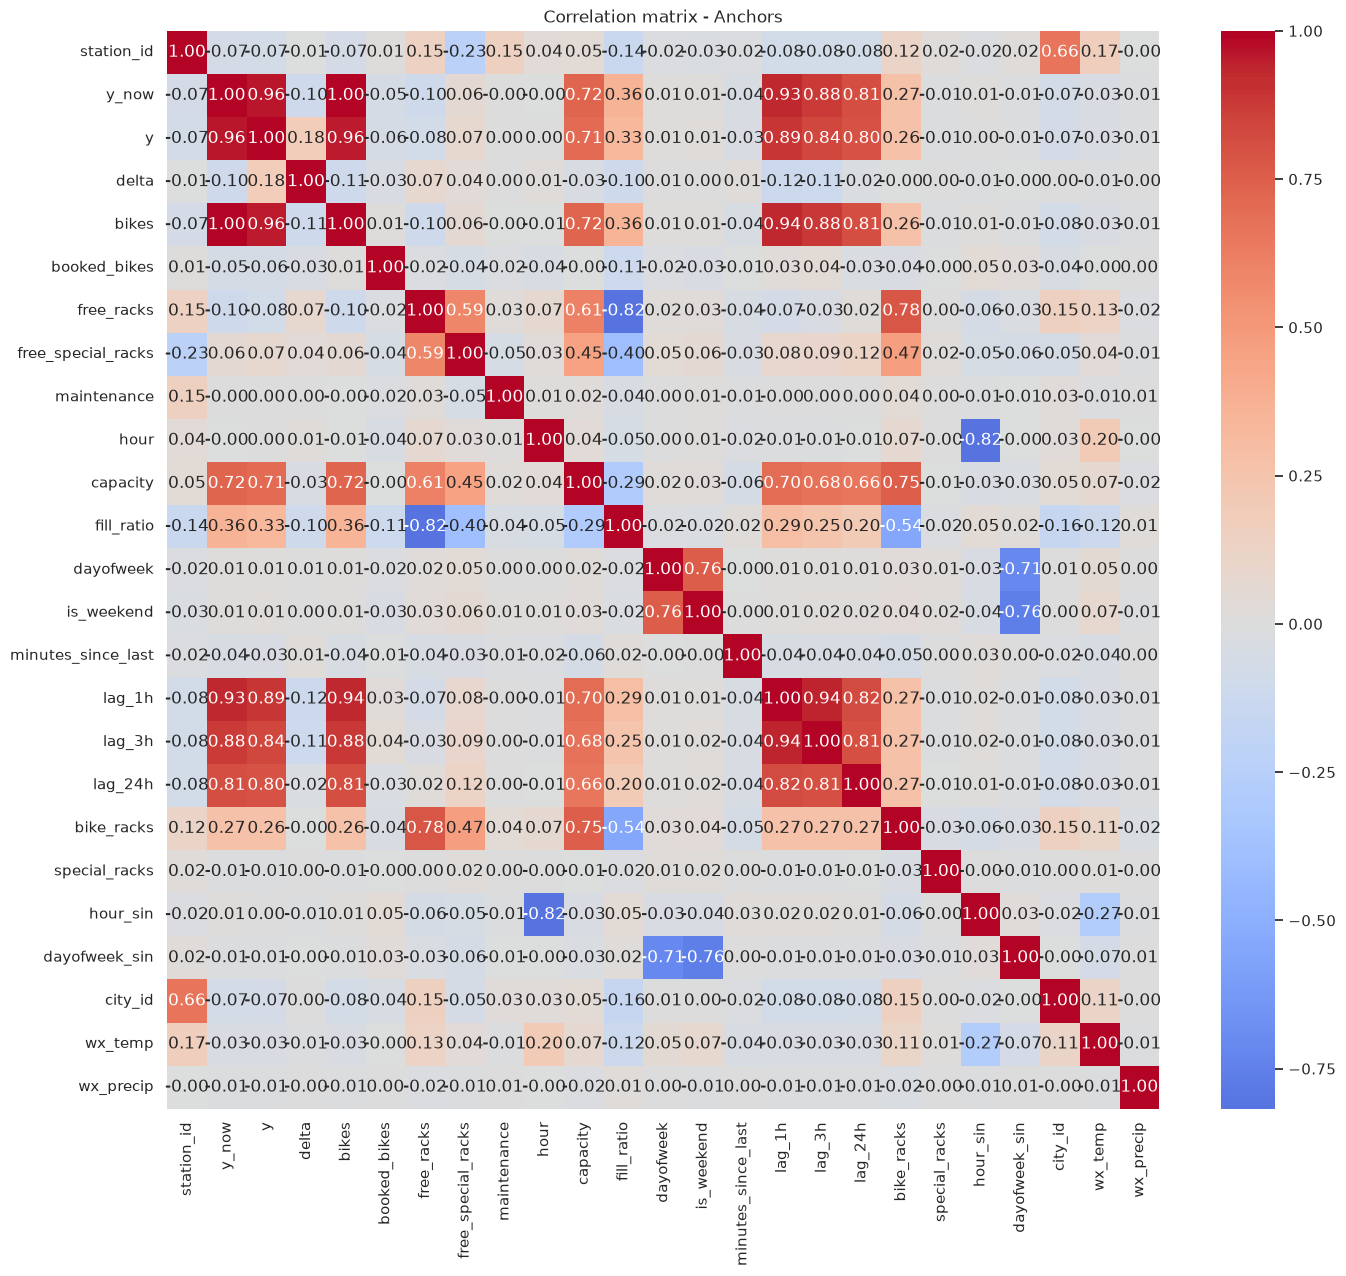

In [31]:
corr = anchors.select_dtypes(include="number").corr()
plt.figure(figsize=(16, 14))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation matrix - Anchors")
plt.show()

In [32]:
low_value_features = ["booked_bikes", "free_special_racks", "hour", "special_racks"]
# Variables that would be better as categorical:
categorical_features = ["maintenance", "dayofweek", "is_weekend"]

In [33]:
# Variables that would be better as categorical:
for c in categorical_features:
    anchors[c] = anchors[c].astype("category")

---
## 5. Baseline

In [34]:
print(stations.columns.tolist())
print(anchors.columns.tolist())

['id', 'city_id', 'terminal_type', 'place_type', 'bike_racks', 'special_racks', 'lon', 'lat']
['station_id', 'time', 'y_now', 'target_time', 'obs_time', 'y', 'delta', 'split', 'bikes', 'booked_bikes', 'free_racks', 'free_special_racks', 'maintenance', 'hour', 'local_time', 'capacity', 'fill_ratio', 'dayofweek', 'is_weekend', 'minutes_since_last', 'lag_1h', 'lag_3h', 'lag_24h', 'bike_racks', 'special_racks', 'hour_sin', 'dayofweek_sin', 'city_id', 'hour_utc', 'wx_temp', 'wx_precip']


In [35]:
features_num = [
    "y_now", "bikes", "free_racks",
    "capacity", "fill_ratio",
    "lag_1h", "lag_3h", "lag_24h",
    "minutes_since_last",
    "hour_sin", "bike_racks",
    "wx_temp",
]
features_cat = ["maintenance", "dayofweek", "is_weekend"]
feature_cols = features_num + features_cat

data = anchors.dropna(subset=feature_cols).reset_index(drop=True)

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

print(f"train: {len(train):,}   test: {len(test):,}")
print(f"features: {len(feature_cols)} ({len(features_num)} numeric + {len(features_cat)} categorical)")

train: 2,125,249   test: 689,748
features: 15 (12 numeric + 3 categorical)


In [36]:
def metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

# Persistence: "in an hour there will be the same as now"
persistence_pred = test["y_now"].to_numpy()
mae_p, rmse_p = metrics(test["y"], persistence_pred)

baselines = pd.DataFrame(
    {"MAE": [mae_p], "RMSE": [rmse_p]},
    index=["Persistence"],
)
baselines.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322


We use persistence as a baseline to compare against the final model, because it's the choice of assuming that in an hour there will be the same as now. We already saw that it's right half the time, so it's a demanding comparison point — any model that doesn't beat this isn't adding anything real.

---
## 6. Models

Both learn to predict `delta` (the change), not `y` directly — that way, "predicting no
change" is exactly equivalent to persistence, and any improvement from the model is interpreted
directly as "how much better than doing nothing."

XGBoost and LightGBM are two *gradient boosting* implementations with the same principle (adding
small trees that correct the error of the previous ones) but with design differences: XGBoost
grows trees level by level, LightGBM grows whichever leaf reduces the error the most first
(*leaf-wise*), which usually makes it faster on large datasets like this one.

In [37]:
X_train, y_train = train[feature_cols], train["delta"]
X_test = test[feature_cols]

xgboost_model = xgb.XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1,
    enable_categorical=True,   # needed because maintenance/dayofweek/is_weekend are "category" dtype
)
xgboost_model.fit(X_train, y_train)
xgb_delta = xgboost_model.predict(X_test)

In [38]:
lgbm = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm.fit(X_train, y_train)
lgbm_delta = lgbm.predict(X_test)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.049027 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1537
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 15
[LightGBM] [Info] Start training from score 0.001021


In [39]:
# The predicted change is added to the current value, and clipped to a physically possible
# range: there can't be fewer than 0 bikes nor more than the station's capacity. Since it's
# a count, it's rounded to the nearest integer.
def to_level(y_now, delta_pred, capacity):
    pred = y_now + delta_pred
    pred = np.clip(pred, 0, capacity)
    return np.round(pred)


xgb_pred = to_level(test["y_now"].to_numpy(), xgb_delta, test["capacity"].to_numpy())
lgbm_pred = to_level(test["y_now"].to_numpy(), lgbm_delta, test["capacity"].to_numpy())

### 6.1 Testing with `y` as a target

The two models above learn `delta` (the change). But several features (especially
`y_now`) have better direct correlation with `y` than with `delta` — which makes sense, because `y`
is almost always very similar to `y_now`, while `delta` is a much smaller and
noisier number. We try a third model, with the same hyperparameters as the LightGBM above,
but trained to predict `y` directly, to compare.

In [40]:
lgbm_y = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm_y.fit(X_train, train["y"])

y_pred_direct = lgbm_y.predict(X_test)
# No need to add y_now here (the model already predicts the final level), just clip it
# to a physically possible range and round it, same as with to_level().
y_pred_direct = np.clip(y_pred_direct, 0, test["capacity"].to_numpy())
y_pred_direct = np.round(y_pred_direct)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.052019 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1537
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 15
[LightGBM] [Info] Start training from score 6.379608


---
## 7. Evaluation on test (data never seen during training)

In [41]:
mae_xgb, rmse_xgb = metrics(test["y"], xgb_pred)
mae_lgbm, rmse_lgbm = metrics(test["y"], lgbm_pred)
mae_direct, rmse_direct = metrics(test["y"], y_pred_direct)

results = pd.concat([
    baselines,
    pd.DataFrame(
        {"MAE": [mae_xgb, mae_lgbm, mae_direct], "RMSE": [rmse_xgb, rmse_lgbm, rmse_direct]},
        index=["XGBoost", "LightGBM", "LightGBM (target y)"],
    ),
])
results.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322
XGBoost,1.0355,1.7599
LightGBM,1.0329,1.7586
LightGBM (target y),1.0341,1.7595


- We have a real but small improvement over persistence in RMSE, but not in MAE.
- Between LightGBM and XGBoost, we'll stick with LightGBM on the delta target — despite the similar results, LightGBM usually trains faster on large datasets like this one. There isn't much difference in interpretability between the two, so I'd go with the faster one.

### 7.1 Feature importance

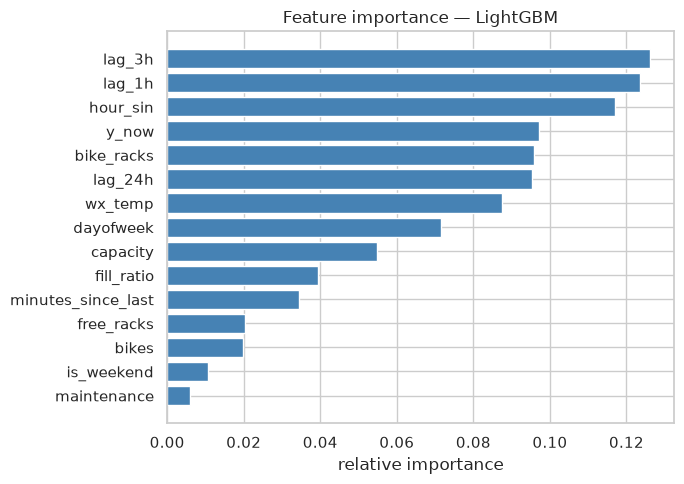

In [42]:
importances = pd.DataFrame({
    "feature": feature_cols,
    "xgboost": xgboost_model.feature_importances_,
    "lightgbm": lgbm.feature_importances_ / lgbm.feature_importances_.sum(),
    "lightgbm_y": lgbm_y.feature_importances_ / lgbm_y.feature_importances_.sum(),
}).sort_values("lightgbm", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("lightgbm")
ax.barh(order["feature"], order["lightgbm"], color="steelblue")
ax.set(title="Feature importance — LightGBM", xlabel="relative importance")
plt.tight_layout()

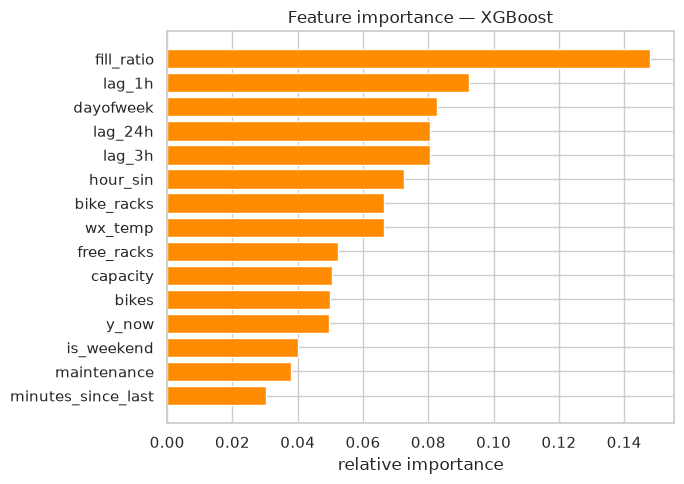

In [43]:
fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("xgboost")
ax.barh(order["feature"], order["xgboost"], color="darkorange")
ax.set(title="Feature importance — XGBoost", xlabel="relative importance")
plt.tight_layout()

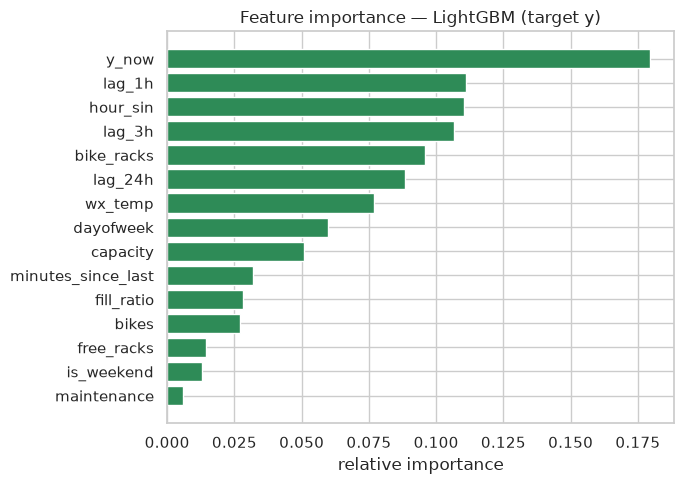

In [44]:
fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("lightgbm_y")
ax.barh(order["feature"], order["lightgbm_y"], color="seagreen")
ax.set(title="Feature importance — LightGBM (target y)", xlabel="relative importance")
plt.tight_layout()

- It depends on the model: for LightGBM the lags dominate (`lag_3h`, `lag_1h`), followed by hour_sin and y_now.
- The temperature variable (`wx_temp`) didn't contribute as much as expected — I thought it would matter more.

### 7.2 Removing low-importance variables

We observed that free_racks, bikes, is_weekend, capacity and maintenance don't contribute much, so we'll remove them and retrain the models to compare.

In [45]:
drop_num = ["bikes", "free_racks", "capacity"]
drop_cat = ["maintenance", "is_weekend"]

features_num_reduced = [c for c in features_num if c not in drop_num]
features_cat_reduced = [c for c in features_cat if c not in drop_cat]
feature_cols_reduced = features_num_reduced + features_cat_reduced

X_train_r = train[feature_cols_reduced]
X_test_r = test[feature_cols_reduced]

print(f"features before: {len(feature_cols)}  ->  features after: {len(feature_cols_reduced)}")

features before: 15  ->  features after: 10


In [46]:
lgbm_r = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm_r.fit(X_train_r, y_train)
lgbm_delta_r = lgbm_r.predict(X_test_r)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018794 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1233
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 10
[LightGBM] [Info] Start training from score 0.001021


In [47]:
lgbm_pred_r = to_level(test["y_now"].to_numpy(), lgbm_delta_r, test["capacity"].to_numpy())
mae_lgbm_r, rmse_lgbm_r = metrics(test["y"], lgbm_pred_r)

comparison = pd.DataFrame(
    {
        "MAE": [mae_p, mae_xgb, mae_lgbm, mae_direct, mae_lgbm_r],
        "RMSE": [rmse_p, rmse_xgb, rmse_lgbm, rmse_direct, rmse_lgbm_r],
    },
    index=[
        "Persistence",
        "XGBoost (all)", "LightGBM (all)", "LightGBM target y (all)",
        "LightGBM (reduced)",
    ],
)
comparison.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322
XGBoost (all),1.0355,1.7599
LightGBM (all),1.0329,1.7586
LightGBM target y (all),1.0341,1.7595
LightGBM (reduced),1.0339,1.7631


- Removing those 5 variables (`free_racks`, `bikes`, `is_weekend`, `capacity`, `maintenance`) makes the model a little worse.
- But, with 10 variables instead of 15 the model is easier to explain and justify in the presentation, and the performance difference is minimal.

### 7.3 Error Analysis

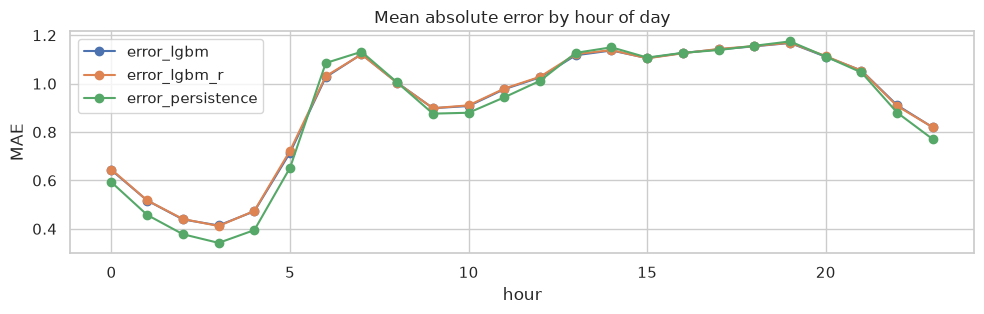

In [48]:
test = test.copy()
test["pred_lgbm"] = lgbm_pred
test["pred_lgbm_r"] = lgbm_pred_r
test["error_lgbm"] = (test["pred_lgbm"] - test["y"]).abs()
test["error_lgbm_r"] = (test["pred_lgbm_r"] - test["y"]).abs()
test["error_persistence"] = (test["y_now"] - test["y"]).abs()

by_hour = test.groupby("hour")[["error_lgbm", "error_lgbm_r", "error_persistence"]].mean()

fig, ax = plt.subplots(figsize=(10, 3.3))
by_hour.plot(ax=ax, marker="o")
ax.set(title="Mean absolute error by hour of day", xlabel="hour", ylabel="MAE")
plt.tight_layout()

- Both LightGBMs (all and reduced) win in almost the same hours: 6-8h (people starting to move in the morning) and 13-20h (afternoon/evening). In those windows there are more real changes to anticipate than in a quiet hour.
- In the early morning (0-5h), mid-morning (9-12h) and at night (21-23h) persistence is better for both models — these are hours where almost nothing happens, so "not changing anything" is already close to optimal. Overall, LightGBM (all) beats persistence in 10 of the 24 hours, and LightGBM (reduced) in 9 of the 24 — a minimal difference, consistent with the reduced model being just slightly weaker.

---
## 8. Evaluation

In [59]:
# 8.1 Load data
EVAL_DIR = ROOT + "/bike_sharing_challenge_2026_eval"
stations_eval = pd.read_csv(EVAL_DIR + "/stations_eval.csv")
status_eval = pd.read_csv(EVAL_DIR + "/stations_status_eval.csv")

In [60]:
print(stations_eval.shape)
stations_eval.head()

(213, 11)


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,139041176,773,KLARA Sparchen,32524,sign,23,1,0,NaN,12.178860,47.590185
1,60956597,266,Parkinsel - Festival des deutschen Films,25064,smart_sign,0,0,0,NaN,8.460106,49.472942
2,66096128,709,Písek - Jaromíra Malého (potraviny),48393,sign,27,0,0,NaN,14.163941,49.311351
3,66097105,709,Písek - V.Kršky/O.Jeremiáše,48398,sign,27,0,0,NaN,14.163458,49.305846
4,66097683,709,Písek - Budějovická (u zastávky),48401,sign,0,0,0,NaN,14.159811,49.301859


In [61]:
print(status_eval.shape)
status_eval.head()

(517787, 8)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,5445382,1.661531e+09,9,0,9,7,7,False
1,50401562,1.661531e+09,5,0,5,7,7,False
2,344835,1.661531e+09,9,0,9,3,0,False
3,5445387,1.661531e+09,4,0,4,12,12,False
4,5445396,1.661531e+09,11,0,11,5,5,False


In [62]:
# 8.2. Formatting the data
# unit="s" because the time comes in epoch (seconds since 1970); it's cast to nanoseconds
# so it combines well with the rest of the notebook in the merge_asof calls below.
status_eval["time"] = pd.to_datetime(status_eval["time"], unit="s", utc=True).astype("datetime64[ns, UTC]")
status_eval["maintenance"] = status_eval["maintenance"].astype(int)

# They don't come with local_time/hour: we need to compute them from each
# station's city timezone (same as was done in the 3.1 cleaning).
status_eval = status_eval.merge(
    stations_eval[["id", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)
status_eval = status_eval.merge(
    cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
    on="city_id", how="left",
)

status_eval["local_time"] = pd.NaT
for tz, idx in status_eval.groupby("timezone").groups.items():
    status_eval.loc[idx, "local_time"] = status_eval.loc[idx, "time"].dt.tz_convert(tz).dt.tz_localize(None)
status_eval["hour"] = status_eval["local_time"].dt.hour

print(f"date range: {status_eval['time'].min()} -> {status_eval['time'].max()}")
print(f"stations also seen in training: {stations_eval['id'].isin(stations['id']).sum()}")

date range: 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00
stations also seen in training: 0


In [ ]:
# The cache from section 4.6 only has the training cities; the evaluation ones are new, so we need to check if any are missing and download them
missing_cities = stations_eval[~stations_eval["city_id"].isin(weather["city_id"])]["city_id"].unique()

missing_cities.shape

(0,)

No missing cities without weather variables

In [64]:
# 8.3. Target
anchors_eval = status_eval[["station_id", "time", "bikes_available_to_rent"]].copy()
anchors_eval = anchors_eval.rename(columns={"bikes_available_to_rent": "y_now"})
anchors_eval["target_time"] = anchors_eval["time"] + pd.Timedelta(hours=1)

future_eval = status_eval[["station_id", "time", "bikes_available_to_rent"]].rename(
    columns={"time": "obs_time", "bikes_available_to_rent": "y"}
).sort_values("obs_time")
anchors_eval = anchors_eval.sort_values("target_time")
anchors_eval = pd.merge_asof(
    anchors_eval, future_eval,
    left_on="target_time", right_on="obs_time",
    by="station_id", direction="backward",
)
anchors_eval["delta"] = anchors_eval["y"] - anchors_eval["y_now"]

In [65]:
# 8.4. Features (only the ones LightGBM reduced uses)
state_cols = ["bikes", "free_racks", "hour", "local_time"]
anchors_eval = anchors_eval.merge(status_eval[["station_id", "time"] + state_cols], on=["station_id", "time"], how="left")

anchors_eval["capacity"] = anchors_eval["bikes"] + anchors_eval["free_racks"]
anchors_eval["fill_ratio"] = anchors_eval["y_now"] / anchors_eval["capacity"].replace(0, np.nan)
anchors_eval["dayofweek"] = anchors_eval["local_time"].dt.dayofweek
anchors_eval["hour_sin"] = np.sin(2 * np.pi * anchors_eval["hour"] / 24)

status_eval["minutes_since_last"] = status_eval.groupby("station_id")["time"].diff().dt.total_seconds() / 60
anchors_eval = anchors_eval.merge(
    status_eval[["station_id", "time", "minutes_since_last"]], on=["station_id", "time"], how="left",
)
anchors_eval["minutes_since_last"] = anchors_eval["minutes_since_last"].fillna(0)

anchors_eval["lag_1h"] = value_n_hours_ago(anchors_eval, status_eval, 1)
anchors_eval["lag_3h"] = value_n_hours_ago(anchors_eval, status_eval, 3)
anchors_eval["lag_24h"] = value_n_hours_ago(anchors_eval, status_eval, 24)
for c in ["lag_1h", "lag_3h", "lag_24h"]:
    anchors_eval[c] = anchors_eval[c].fillna(anchors_eval["y_now"])

anchors_eval = anchors_eval.merge(
    stations_eval[["id", "bike_racks", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

# Weather
anchors_eval["hour_utc"] = anchors_eval["time"].dt.floor("h")
anchors_eval = anchors_eval.merge(
    weather[["city_id", "weather_time", "wx_temp"]].rename(columns={"weather_time": "hour_utc"}),
    on=["city_id", "hour_utc"], how="left",
)

In [ ]:
# 8.5. Prediction with reduced LightGBM
data_eval = anchors_eval.dropna(subset=feature_cols_reduced + ["capacity"]).reset_index(drop=True)

data_eval["dayofweek"] = pd.Categorical(data_eval["dayofweek"], categories=range(7))
X_eval = data_eval[feature_cols_reduced]

lgbm_delta_eval = lgbm_r.predict(X_eval)
data_eval["lgbm_pred"] = to_level(data_eval["y_now"].to_numpy(), lgbm_delta_eval, data_eval["capacity"].to_numpy())

persistence_pred_eval = data_eval["y_now"].to_numpy()
mae_p_eval, rmse_p_eval = metrics(data_eval["y"], persistence_pred_eval)
mae_lgbm_eval, rmse_lgbm_eval = metrics(data_eval["y"], data_eval["lgbm_pred"])

results_eval = pd.DataFrame(
    {"MAE": [mae_p_eval, mae_lgbm_eval], "RMSE": [rmse_p_eval, rmse_lgbm_eval]},
    index=["Persistence", "LightGBM (reduced)"],
)
print(f"rows evaluated: {len(data_eval):,}  (out of {len(stations_eval)} stations never seen in training)")
results_eval.round(4)

rows evaluated: 505,299  (out of 213 stations never seen in training)


,MAE,RMSE
Persistence,1.4471,2.9696
LightGBM (reduced),1.4456,2.8873


- On the 213 new, never-seen stations we get MAE 1.4456 / RMSE 2.8873, beating the persistence baseline.